# 完整流程示例（对照 CLI）

路径用 `meteva_base.get_path`。数据根目录为 `resource/data/`。

风速用最新的 0.1° 等高层结果：`wind/YYYY/YYYYMMDD/YYYYMMDDHH.TTT.nc`。10 m 和 100 m 来自近地面 U/V，200 m 及以上由等压层结合 100 m 风插值，各层没有缺测。订正使用 1 km 的目标地形、模式地形、sigma、轮廓粗糙度和植被粗糙度。调用前把 0.1° 风速双线性插到这套 1 km 网格上，使高分辨率地形能够订正风速。`standard_orography_1km.nc` 只读取。`model_resolution` 填模式间距 **20000 m**。格距 `ppres` 按 1 km 网格计算。

整幅 1 km 廓线约 1.2 GB，订正时还会再复制。下面按纬度每 150 行插值并订正，每块只保留 10 m，拼回后放入 `corrected`。

**时次**：EC 为世界时，文件名 `YYYYMMDDHH.TTT.nc`。实况 HRCLDAS 文件名是北京时，取有效世界时加 8 小时。列表和后面的单元格必须在同一次内核会话里运行。

## 1. 准备

In [1]:
from __future__ import annotations

import sys
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import meteva_base as meb
import xarray as xr

# 包根 = nbs 的上一级；00temp 用于 import
PKG = Path("..").resolve()
sys.path[:0] = [str(PKG.parent), str(PKG)]

from orographic_wind_downscaling.src.wind_downscaling import RoughnessCorrection

DATA = PKG / "resource" / "data"
OBS_ROOT = DATA / "hrcldas_wind"

WIND_TPL = str(DATA / "wind" / "YYYY" / "YYYYMMDD" / "YYYYMMDDHH.TTT.nc")

SIGMA = str(DATA / "sigma.nc")
TARGET_OROG = str(DATA / "HGT_M_1KM_CHINA.nc")
SILHOUETTE = str(DATA / "silhouette_roughness.nc")
Z0 = str(DATA / "vegetative_roughness_z0.nc")
STANDARD_OROG = str(DATA / "standard_orography_1km.nc")
MODEL_RESOLUTION = 20000.0
OUTPUT_HEIGHT_M = 10.0
LAT_CHUNK = 150

FIG = DATA / "output" / "figs"
FIG.mkdir(parents=True, exist_ok=True)

cases = []
for path in sorted((DATA / "wind").glob("????/????????/*.nc")):
    init_text, lead_text = path.stem.split(".")
    cases.append((datetime.strptime(init_text, "%Y%m%d%H"), int(lead_text)))
print("n cases", len(cases))
print("example wind:", meb.get_path(WIND_TPL, cases[0][0], cases[0][1]))

d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


n cases 32
example wind: D:\workspace\test\00temp\orographic_wind_downscaling\resource\data\wind\2026\20260831\2026083100.000.nc


## 2. 批量订正

`corrected` 与 `cases` 顺序一致，每个元素是该时次订正后的 10 m 风速。静态场保持 1 km，只读一次。每个时次先把 0.1° 风速按纬度块双线性插到 1 km，再订正，避免整幅廓线同时进入内存。

In [2]:
from scipy.ndimage import map_coordinates

sigma = meb.read_griddata_from_nc(SIGMA)
target = meb.read_griddata_from_nc(TARGET_OROG)
standard = meb.read_griddata_from_nc(STANDARD_OROG)
silhouette = meb.read_griddata_from_nc(SILHOUETTE)
z0 = meb.read_griddata_from_nc(Z0)
ppres = RoughnessCorrection.infer_grid_resolution_from_coords(target)
n_lat = int(target.sizes["lat"])
n_lon = int(target.sizes["lon"])
lat_1km = np.asarray(target.lat.values, dtype=np.float64)
lon_1km = np.asarray(target.lon.values, dtype=np.float64)
print("ppres_m", round(ppres, 1), "n_lat", n_lat, "n_lon", n_lon)


def _slab(field: xr.DataArray, sl: slice) -> np.ndarray:
    """取出纬度块。用数组而不是 DataArray，避免 meteva 把超过 1000 m 的地形改成缺测。"""
    return np.squeeze(np.asarray(field.isel(lat=sl).values, dtype=np.float32))


def _load_wind(wind_path: str):
    with xr.open_dataset(wind_path) as wind_ds:
        speed = np.squeeze(np.asarray(wind_ds["wind_speed"].values, dtype=np.float32))
        levels = np.asarray(wind_ds["level"].values, dtype=np.float32)
        lat = np.asarray(wind_ds["lat"].values, dtype=np.float64)
        lon = np.asarray(wind_ds["lon"].values, dtype=np.float64)
    return speed, levels, lat, lon


def _sample_coords(lat_src, lon_src, lat_dst, lon_dst) -> np.ndarray:
    y = (lat_dst - lat_src[0]) / (lat_src[1] - lat_src[0])
    x = (lon_dst - lon_src[0]) / (lon_src[1] - lon_src[0])
    y = np.clip(y, 0.0, lat_src.size - 1)
    x = np.clip(x, 0.0, lon_src.size - 1)
    yy, xx = np.meshgrid(y, x, indexing="ij")
    return np.vstack((yy.ravel(), xx.ravel()))


def _bilinear(plane: np.ndarray, coords: np.ndarray, nlat: int, nlon: int) -> np.ndarray:
    return map_coordinates(plane, coords, order=1, mode="nearest").reshape(nlat, nlon).astype(np.float32)


def interp_10m(wind_path: str) -> np.ndarray:
    """把 0.1° 的 10 m 风速双线性插到 1 km 目标地形网格。"""
    speed, levels, lat_src, lon_src = _load_wind(wind_path)
    level_index = int(np.where(np.isclose(levels, OUTPUT_HEIGHT_M))[0][0])
    out = np.empty((n_lat, n_lon), dtype=np.float32)
    for i0 in range(0, n_lat, LAT_CHUNK):
        i1 = min(i0 + LAT_CHUNK, n_lat)
        coords = _sample_coords(lat_src, lon_src, lat_1km[i0:i1], lon_1km)
        out[i0:i1] = _bilinear(speed[level_index], coords, i1 - i0, n_lon)
    return out


def correct_10m(wind_path: str) -> xr.DataArray:
    """0.1° 廓线按纬度块插到 1 km 后订正，只返回 10 m。"""
    speed, levels, lat_src, lon_src = _load_wind(wind_path)
    level_index = int(np.where(np.isclose(levels, OUTPUT_HEIGHT_M))[0][0])
    out = np.empty((n_lat, n_lon), dtype=np.float32)
    for i0 in range(0, n_lat, LAT_CHUNK):
        i1 = min(i0 + LAT_CHUNK, n_lat)
        sl = slice(i0, i1)
        coords = _sample_coords(lat_src, lon_src, lat_1km[sl], lon_1km)
        wind_values = np.empty((speed.shape[0], i1 - i0, n_lon), dtype=np.float32)
        for k in range(speed.shape[0]):
            wind_values[k] = _bilinear(speed[k], coords, i1 - i0, n_lon)
        plugin = RoughnessCorrection(
            _slab(silhouette, sl),
            _slab(sigma, sl),
            _slab(target, sl),
            _slab(standard, sl),
            MODEL_RESOLUTION,
            ppres=ppres,
            z0=_slab(z0, sl),
        )
        result = plugin.process(wind_values, height_grid=levels)
        out[i0:i1] = result[level_index]
        del result, plugin, wind_values
    return meb.grid_data(grid1km, data=out)


grid1km = meb.get_grid_of_data(target)
corrected = []
for t0, lead in cases:
    corrected.append(correct_10m(meb.get_path(WIND_TPL, t0, lead)))
    print("corr", t0.strftime("%Y%m%d%H") + f".{lead:03d}", "n", len(corrected))
print("correct done", len(corrected))

ppres_m 997.1 n_lat 4461 n_lon 6961
corr 2026083100.000 n 1
corr 2026083100.003 n 2
corr 2026083100.006 n 3
corr 2026083100.009 n 4
corr 2026083100.012 n 5
corr 2026083100.015 n 6
corr 2026083100.018 n 7
corr 2026083100.021 n 8
corr 2026090100.000 n 9
corr 2026090100.003 n 10
corr 2026090100.006 n 11
corr 2026090100.009 n 12
corr 2026090100.012 n 13
corr 2026090100.015 n 14
corr 2026090100.018 n 15
corr 2026090100.021 n 16
corr 2026090200.000 n 17
corr 2026090200.003 n 18
corr 2026090200.006 n 19
corr 2026090200.009 n 20
corr 2026090200.012 n 21
corr 2026090200.015 n 22
corr 2026090200.018 n 23
corr 2026090200.021 n 24
corr 2026090300.000 n 25
corr 2026090300.003 n 26
corr 2026090300.006 n 27
corr 2026090300.009 n 28
corr 2026090300.012 n 29
corr 2026090300.015 n 30
corr 2026090300.018 n 31
corr 2026090300.021 n 32
correct done 32


## 3. 三张图（抽第 1 个时次的 10 m）

1 订正前　2 订正后　3 实况。三张图共用同一套色标。订正后取 `corrected[0]`。

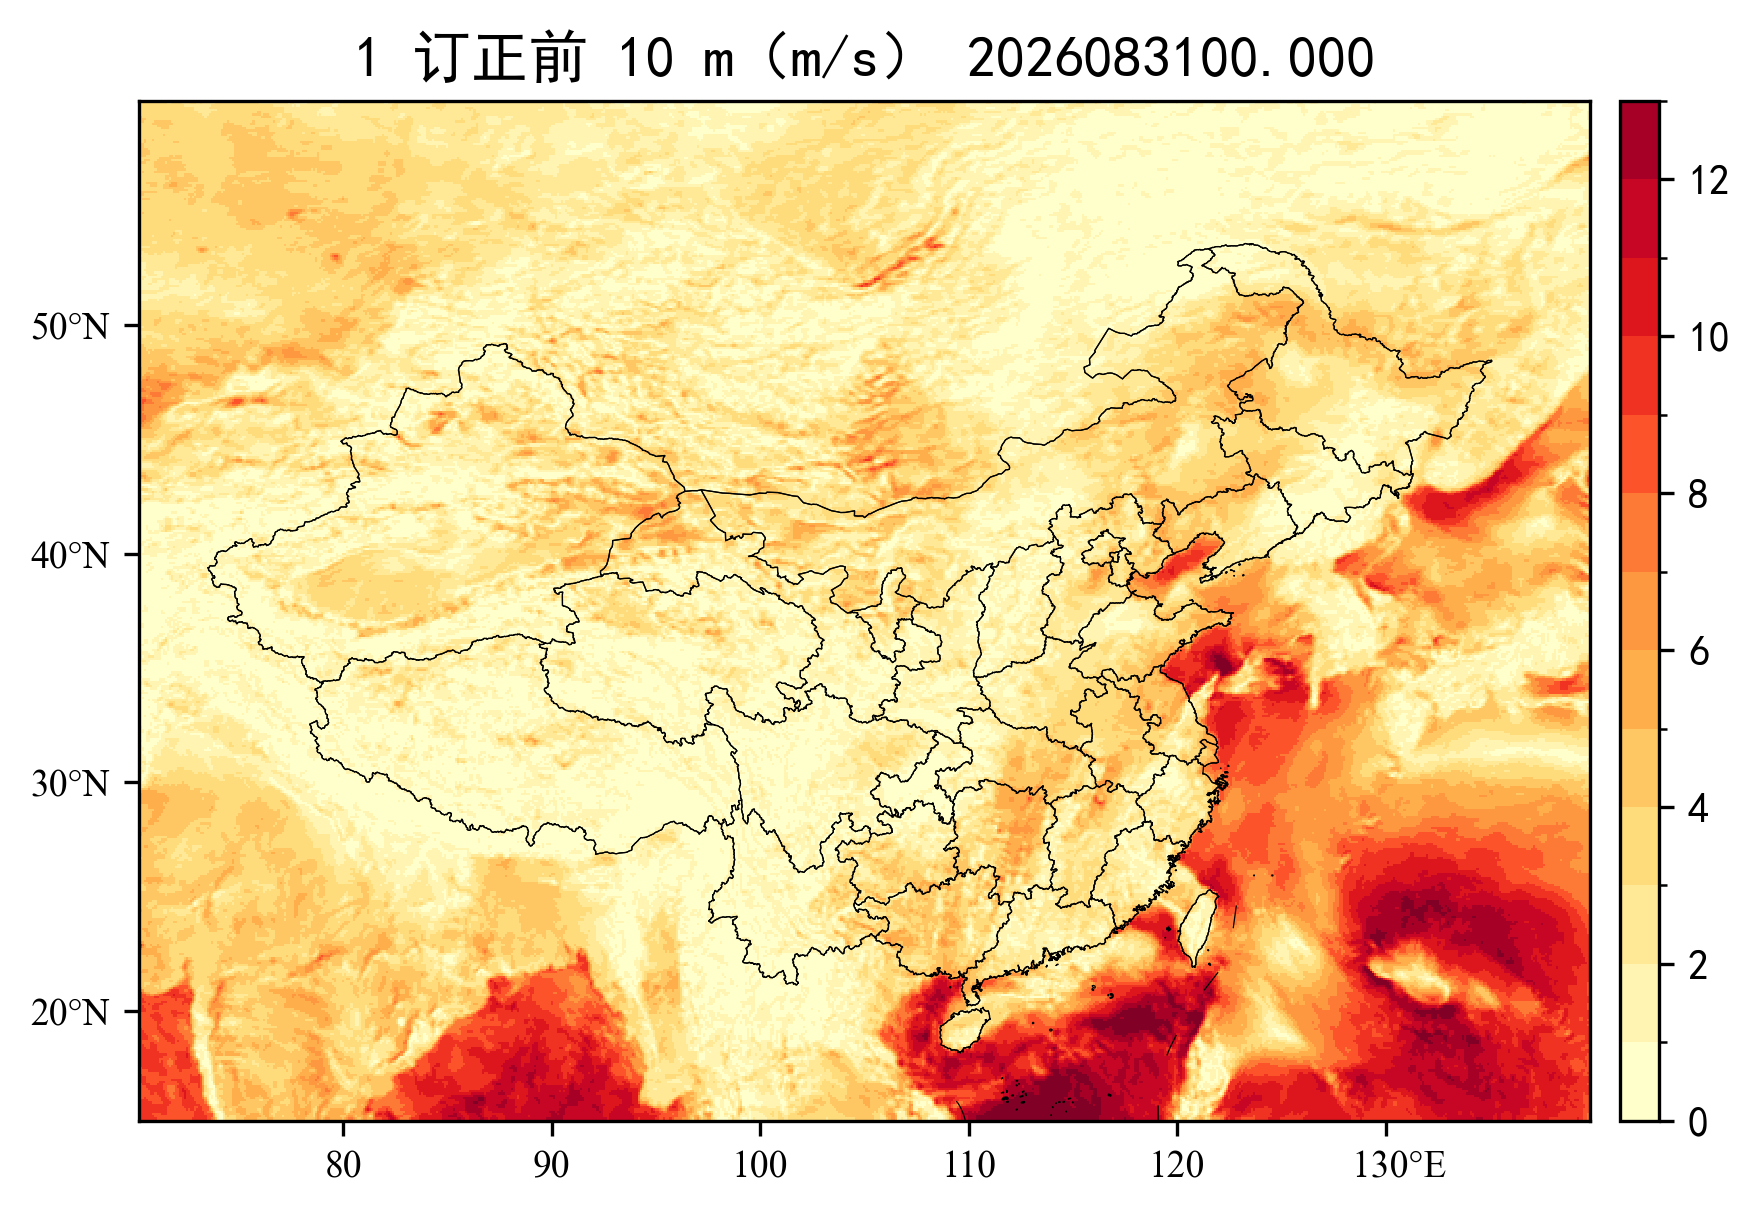

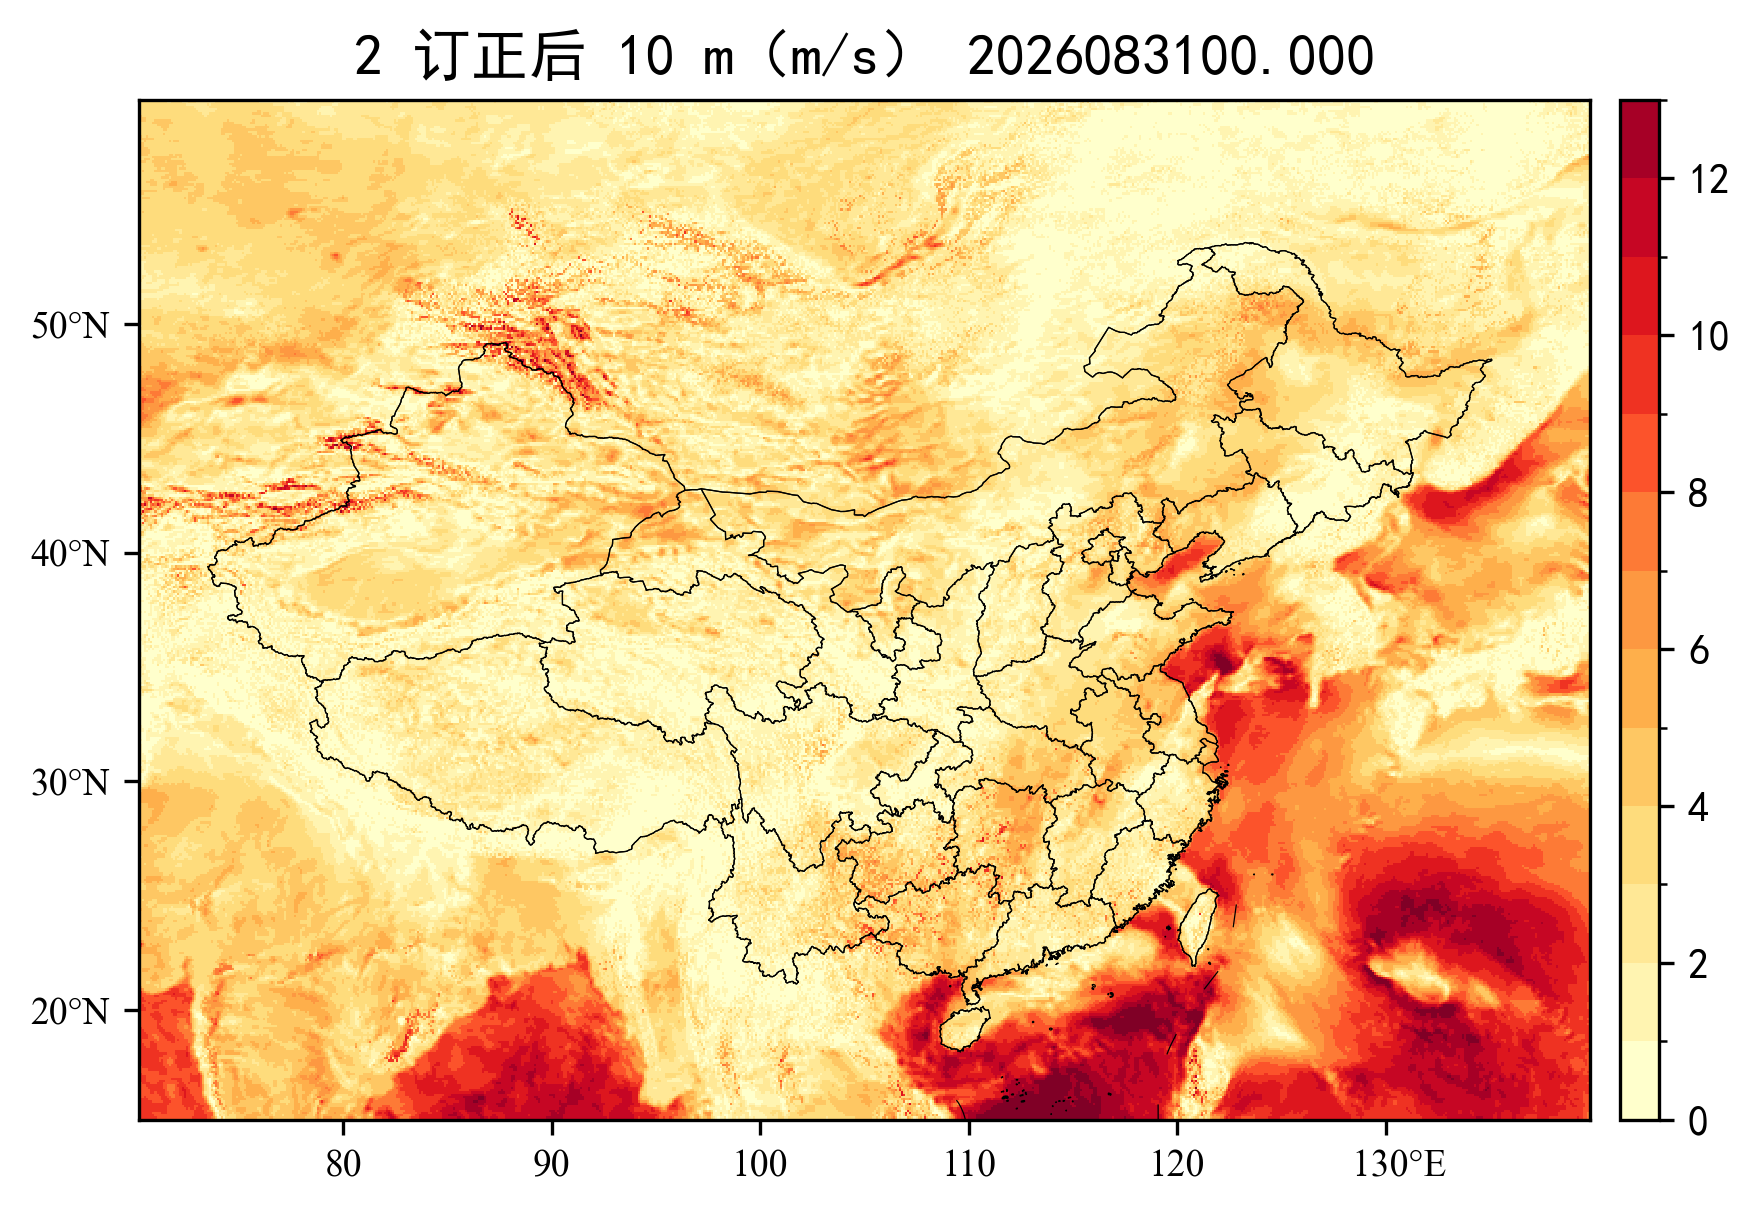

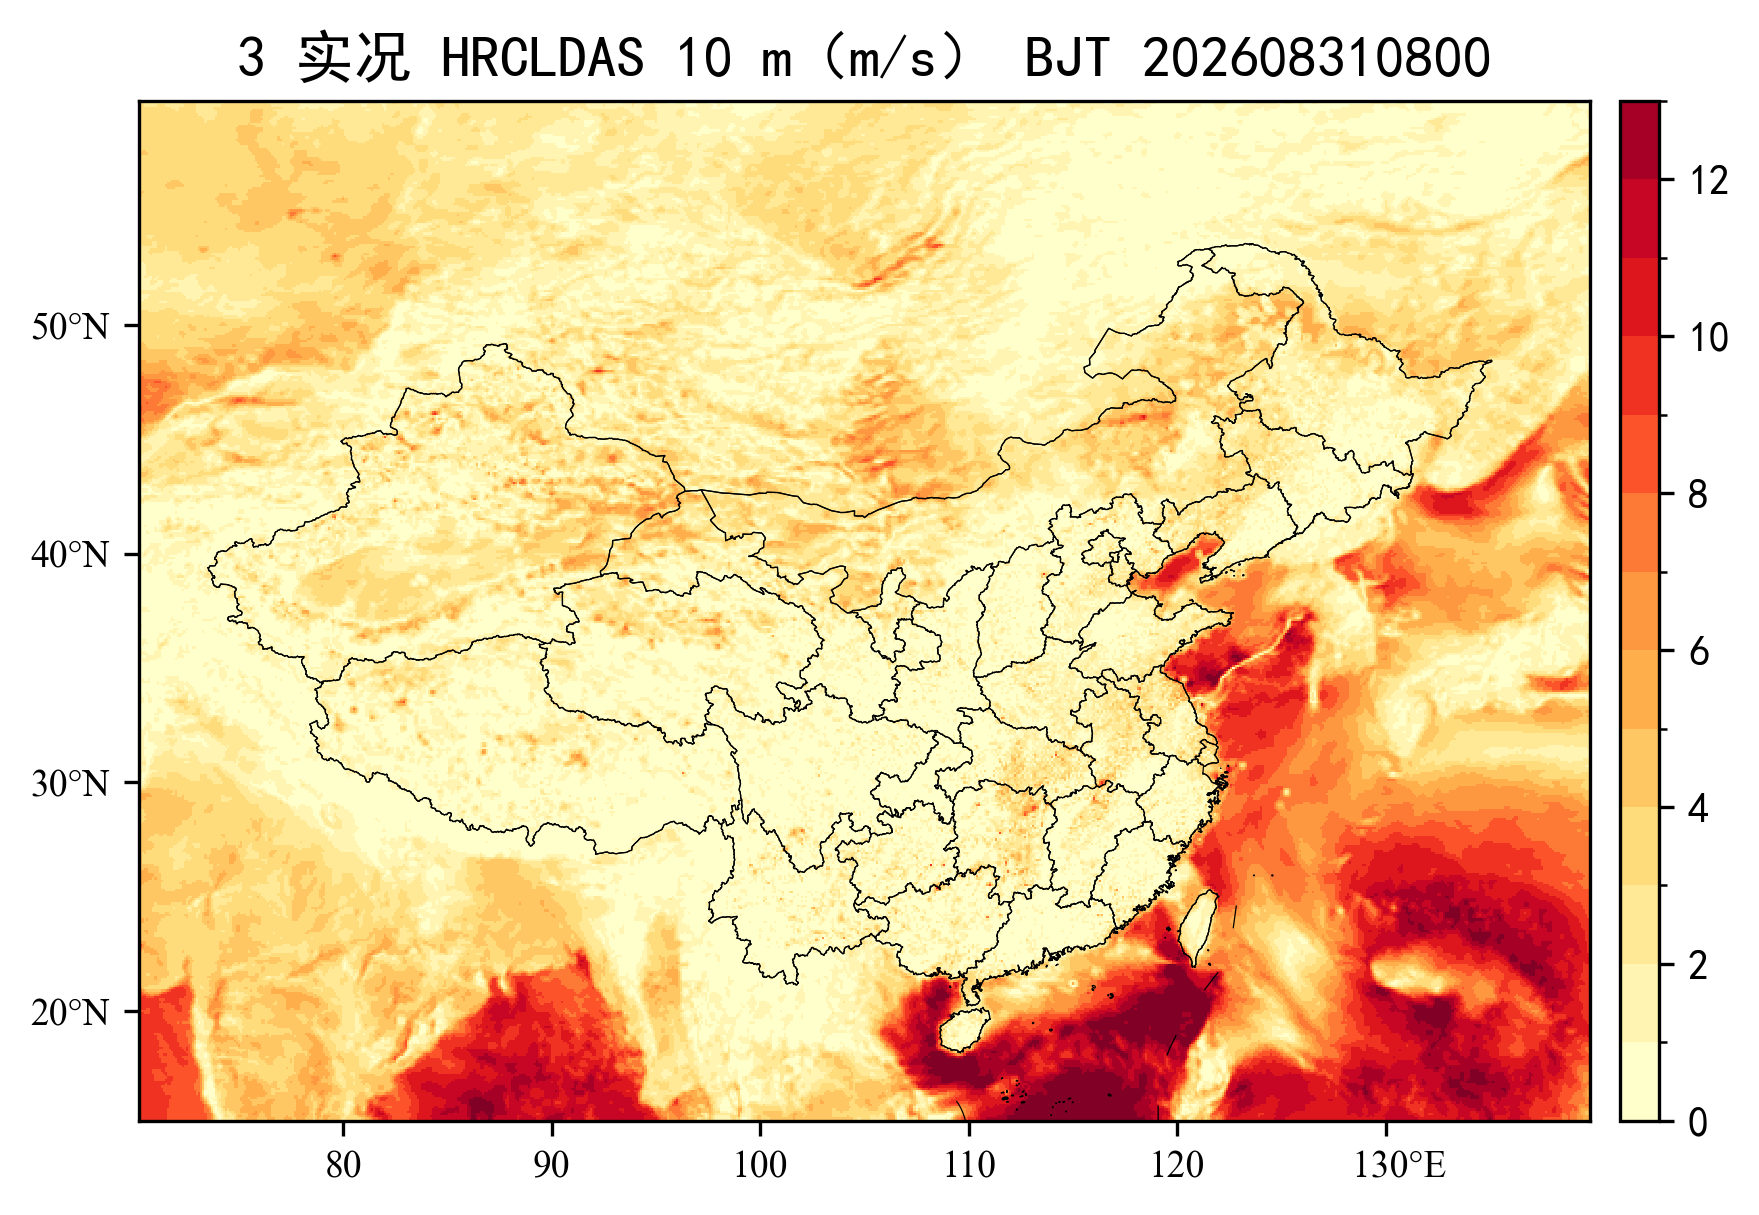

figs: D:\workspace\test\00temp\orographic_wind_downscaling\resource\data\output\figs


In [3]:
from meteva_base.tool.plot_tools import pcolormesh_2d_grid

t0, lead = cases[0]
tag = t0.strftime("%Y%m%d%H") + f".{lead:03d}"
valid = t0 + timedelta(hours=lead)
bjt = valid + timedelta(hours=8)
step = 10

before = meb.grid_data(
    grid1km,
    data=interp_10m(meb.get_path(WIND_TPL, t0, lead)),
)
before = before.isel(lat=slice(None, None, step), lon=slice(None, None, step))
before.name = "wind_speed"
before.attrs["units"] = "m s-1"

after = corrected[0].isel(lat=slice(None, None, step), lon=slice(None, None, step))
after.name = "wind_speed"
after.attrs["units"] = "m s-1"

day, hhmm = bjt.strftime("%Y%m%d"), bjt.strftime("%H%M")
obs_path = next((OBS_ROOT / bjt.strftime("%Y") / day).glob(f"*WIND-{day}{hhmm}.GRB2"))
obs_da = xr.open_dataset(str(obs_path), engine="cfgrib")["si10"]
dest = target
obs_da = obs_da.sel(
    latitude=slice(float(dest.lat.min()), float(dest.lat.max())),
    longitude=slice(float(dest.lon.min()), float(dest.lon.max())),
).reindex(
    latitude=dest.lat.values,
    longitude=dest.lon.values,
    method="nearest",
    tolerance=0.006,
)
obs = meb.grid_data(meb.get_grid_of_data(dest), data=np.asarray(obs_da.values, dtype=np.float32))
obs = obs.isel(lat=slice(None, None, step), lon=slice(None, None, step))
obs.name = "wind_speed"
obs.attrs["units"] = "m s-1"

both = np.concatenate([
    np.asarray(before.values, dtype=float).ravel(),
    np.asarray(after.values, dtype=float).ravel(),
    np.asarray(obs.values, dtype=float).ravel(),
])
both = both[np.isfinite(both)]
vmin = np.floor(np.nanpercentile(both, 1))
vmax = np.ceil(np.nanpercentile(both, 99))
cstep = 1.0
clevs = np.arange(vmin, vmax + 0.1, cstep)
while len(clevs) >= 20:
    cstep *= 2
    clevs = np.arange(vmin, vmax + 0.1, cstep)
clevs = clevs.tolist()

pcolormesh_2d_grid(
    before, save_path=str(FIG / f"{tag}_1_before.png"),
    title=f"1 订正前 10 m（m/s） {tag}", clevs=clevs, cmap="YlOrRd", show=True,
)
pcolormesh_2d_grid(
    after, save_path=str(FIG / f"{tag}_2_after.png"),
    title=f"2 订正后 10 m（m/s） {tag}", clevs=clevs, cmap="YlOrRd", show=True,
)
pcolormesh_2d_grid(
    obs, save_path=str(FIG / f"{tag}_3_obs.png"),
    title=f"3 实况 HRCLDAS 10 m（m/s） BJT {bjt:%Y%m%d%H%M}",
    clevs=clevs, cmap="YlOrRd", show=True,
)
print("figs:", FIG)

## 4. 验证 Bias / RMSE（订正前 / 订正后 vs 实况）

- **订正前**：0.1° 风速插到 1 km 后的 10 m，也就是进入订正的场。
- **订正后**：`corrected` 里对应时次的 10 m。
- 实况为 HRCLDAS 10 m 风速，取到同一套 1 km 点。订正前、订正后分别与实况的有限值计算。ΔRMSE = 订正后 − 订正前，负值表示改善。

In [4]:
def _bias_rmse(pred: np.ndarray, obs: np.ndarray) -> tuple[float, float]:
    mask = np.isfinite(pred) & np.isfinite(obs)
    diff = pred[mask] - obs[mask]
    return float(np.mean(diff)), float(np.sqrt(np.mean(diff**2)))


if len(corrected) != len(cases):
    raise RuntimeError(f"corrected 有 {len(corrected)} 个时次，cases 有 {len(cases)} 个")

dest = target
rows = []
for (t0, lead), after in zip(cases, corrected):
    tag = t0.strftime("%Y%m%d%H") + f".{lead:03d}"
    bjt = t0 + timedelta(hours=lead + 8)
    day, hhmm = bjt.strftime("%Y%m%d"), bjt.strftime("%H%M")
    obs_path = next((OBS_ROOT / bjt.strftime("%Y") / day).glob(f"*WIND-{day}{hhmm}.GRB2"))
    obs_da = xr.open_dataset(str(obs_path), engine="cfgrib")["si10"]
    obs_da = obs_da.sel(
        latitude=slice(float(dest.lat.min()), float(dest.lat.max())),
        longitude=slice(float(dest.lon.min()), float(dest.lon.max())),
    ).reindex(
        latitude=dest.lat.values,
        longitude=dest.lon.values,
        method="nearest",
        tolerance=0.006,
    )

    before_values = interp_10m(meb.get_path(WIND_TPL, t0, lead)).ravel()
    obs_values = np.asarray(obs_da.values, dtype=float).ravel()
    after_values = np.asarray(after.values, dtype=float).ravel()
    bias0, rmse0 = _bias_rmse(before_values, obs_values)
    bias1, rmse1 = _bias_rmse(after_values, obs_values)
    rows.append((tag, bias0, rmse0, bias1, rmse1))
    print(
        f"{tag}  before bias={bias0:.3f} m/s rmse={rmse0:.3f} m/s | "
        f"after bias={bias1:.3f} m/s rmse={rmse1:.3f} m/s | "
        f"Δrmse={rmse1 - rmse0:+.3f} m/s"
    )

mean_b0 = float(np.mean([row[1] for row in rows]))
mean_r0 = float(np.mean([row[2] for row in rows]))
mean_b1 = float(np.mean([row[3] for row in rows]))
mean_r1 = float(np.mean([row[4] for row in rows]))
print(
    f"mean  before bias={mean_b0:.3f} m/s rmse={mean_r0:.3f} m/s | "
    f"after bias={mean_b1:.3f} m/s rmse={mean_r1:.3f} m/s | "
    f"Δrmse={mean_r1 - mean_r0:+.3f} m/s"
)

2026083100.000  before bias=0.150 m/s rmse=1.012 m/s | after bias=0.333 m/s rmse=1.378 m/s | Δrmse=+0.366 m/s
2026083100.003  before bias=0.225 m/s rmse=1.081 m/s | after bias=0.202 m/s rmse=1.289 m/s | Δrmse=+0.208 m/s
2026083100.006  before bias=0.282 m/s rmse=1.171 m/s | after bias=0.097 m/s rmse=1.316 m/s | Δrmse=+0.145 m/s
2026083100.009  before bias=0.269 m/s rmse=0.873 m/s | after bias=0.167 m/s rmse=1.085 m/s | Δrmse=+0.212 m/s
2026083100.012  before bias=0.215 m/s rmse=0.830 m/s | after bias=0.404 m/s rmse=1.234 m/s | Δrmse=+0.403 m/s
2026083100.015  before bias=0.198 m/s rmse=0.808 m/s | after bias=0.493 m/s rmse=1.364 m/s | Δrmse=+0.556 m/s
2026083100.018  before bias=0.204 m/s rmse=0.799 m/s | after bias=0.498 m/s rmse=1.394 m/s | Δrmse=+0.595 m/s
2026083100.021  before bias=0.240 m/s rmse=1.180 m/s | after bias=0.518 m/s rmse=1.647 m/s | Δrmse=+0.467 m/s
2026090100.000  before bias=0.184 m/s rmse=1.113 m/s | after bias=0.416 m/s rmse=1.582 m/s | Δrmse=+0.469 m/s
2026090100

上一格运行后，各时次的 bias 和 RMSE 显示在该格的输出里。先前 wind_1km 的评分对应另一套输入，这里不再保留。
